In [1]:
import fdfi
print('FDFI version:', fdfi.__version__)

FDFI version: 0.2.1


# FlowExplainer: Flow-Disentangled Feature Importance

This tutorial covers the `FlowExplainer`, which uses **normalizing flows** to compute feature importance. By the end, you'll understand:

1. How Flow-DFI differs from OT-based methods
2. The difference between CPI and SCPI methods
3. How to use FlowExplainer with default and custom flow models
4. When to choose FlowExplainer over OTExplainer

## Setup

First, let's import the necessary libraries:

In [2]:
import sys
sys.path.insert(0, '../..')  # Add project root to path

import numpy as np
import warnings
warnings.filterwarnings('ignore')

from fdfi.explainers import FlowExplainer, OTExplainer
from fdfi.plots import confidence_interval_plot, diagnostics_plot, summary_bar

# Set random seed for reproducibility
np.random.seed(42)



## Background: Why Flow-DFI?

**OTExplainer** and **EOTExplainer** use optimal transport to create a disentangled representation. However, they rely on parametric assumptions (Gaussian or kernel-based).

**FlowExplainer** uses a **normalizing flow** — a learned neural network that maps between the original feature space X and a disentangled latent space Z. This is:

- **More flexible**: Learns complex non-linear transformations
- **Data-driven**: No parametric assumptions
- **Invertible**: Can map X → Z and Z → X

The tradeoff is that it requires training a neural network, which takes longer.

## Create Test Data

Let's create data with correlated features where only some features are truly important:

In [3]:
# Create correlated features
n_samples = 500
n_features = 8

# Covariance matrix with correlations
cov = np.eye(n_features)
cov[0, 1] = cov[1, 0] = 0.7  # Features 0 and 1 are correlated
cov[2, 3] = cov[3, 2] = 0.5  # Features 2 and 3 are correlated

X = np.random.multivariate_normal(np.zeros(n_features), cov, size=n_samples)

# Model: only features 0, 1, 2 are active
def model(X):
    return X[:, 0] + 2 * X[:, 1] + 0.5 * X[:, 2]

# Split into train/test
X_train, X_test = X[:400], X[400:]

print(f"Training data: {X_train.shape}")
print(f"Test data: {X_test.shape}")
print(f"\nActive features: 0, 1, 2")
print(f"Null features: 3, 4, 5, 6, 7")

Training data: (400, 8)
Test data: (100, 8)

Active features: 0, 1, 2
Null features: 3, 4, 5, 6, 7


## Basic Usage: CPI Method (Default)

The simplest way to use FlowExplainer is with the default CPI (Conditional Permutation Importance) method:

In [4]:
# Create FlowExplainer with CPI method
explainer_cpi = FlowExplainer(
    model,
    data=X_train,
    method='cpi',        # Conditional Permutation Importance
    nsamples=30,         # Monte Carlo samples per feature
    num_steps=200,       # Flow training steps (use more for better results)
    random_state=42,
)

# Compute importance
results_cpi = explainer_cpi(X_test)

print("\nCPI Feature Importance:")
print("-" * 40)
for i, phi in enumerate(results_cpi.get_phi_X()):
    marker = "*" if i < 3 else ""  # Mark active features
    print(f"  Feature {i}: {phi:8.4f} {marker}")
print("\n* = active feature")

[FDFI][INFO] Training flow model...


Training complete: 200 steps, final loss=1.7161
[FDFI][DIAG] Flow Model Diagnostics
[FDFI][DIAG] Latent independence (median dCor): 0.083235 [GOOD]  -> lower is better
[FDFI][DIAG] Distribution fidelity (MMD):       0.000000 [GOOD]  -> lower is better



CPI Feature Importance:
----------------------------------------
  Feature 0:   7.4857 *
  Feature 1:  10.6929 *
  Feature 2:   0.3499 *
  Feature 3:   0.0833 
  Feature 4:   0.0317 
  Feature 5:   0.0088 
  Feature 6:   0.0323 
  Feature 7:   0.0109 

* = active feature


## CPI vs SCPI: What's the Difference?

FlowExplainer provides two resampling methods for computing importance in the **latent Z-space**, using the definitions in the FDFI paper and a configurable per-sample loss $L$ (default: squared error).

**CPI (Conditional Permutation Importance)**
- Apply the loss to each counterfactual, average the loss differences, and multiply by one half
- Formula: $\phi_{Z,j}^{CPI} = \tfrac12\mathbb{E}_b[L(Y,f(\tilde X_b^{(j)}))-L(Y,f(X))]$

**SCPI (Sobol-CPI)**
- Average the counterfactual predictions first, then apply the loss difference
- Formula: $\phi_{Z,j}^{SCPI} = L(Y,\mathbb{E}_b[f(\tilde X_b^{(j)})])-L(Y,f(X))$

The one-half factor is the normalized CPI convention of the FDFI paper; conventional CPI is twice as large. For the same finite draws and **squared-error loss**, the exact relationship is:

$$2\widehat\phi_{Z,j}^{CPI} = \widehat\phi_{Z,j}^{SCPI} + \text{Var}_b[f(\tilde{X}_b^{(j)})]$$

With exact latent independence and a Bayes predictor, normalized CPI and infinite-resample SCPI have the same population target. At finite $B$, uncorrected squared-loss SCPI has the familiar $(1+1/B)$ Monte Carlo inflation in that ideal setting.

**Jacobian Transformation to X-space**

Both methods compute importance in Z-space (disentangled features). To attribute importance to the **original features** $X_l$, FlowExplainer uses the **Jacobian** $H = \frac{\partial X}{\partial Z}$:

$$\phi_{X,l} = \sum_{k=1}^{d} H_{lk}^2 \cdot \phi_{Z,k}$$

This correctly accounts for how each latent dimension affects each original feature.

In [5]:
# Create FlowExplainer with SCPI method
explainer_scpi = FlowExplainer(
    model,
    data=X_train,
    method='scpi',       # Sobol-CPI
    nsamples=30,
    num_steps=200,
    random_state=42,
)

results_scpi = explainer_scpi(X_test)

# Compare CPI vs SCPI
print("Comparison: CPI vs SCPI")
print("-" * 50)
print(f"{'Feature':>8} {'CPI':>12} {'SCPI':>12} {'Active':>10}")
print("-" * 50)
for i in range(n_features):
    active = "Yes" if i < 3 else "No"
    print(f"{i:>8} {results_cpi.get_phi_X()[i]:>12.4f} {results_scpi.get_phi_X()[i]:>12.4f} {active:>10}")

[FDFI][INFO] Training flow model...


Training complete: 200 steps, final loss=1.7161
[FDFI][DIAG] Flow Model Diagnostics
[FDFI][DIAG] Latent independence (median dCor): 0.083235 [GOOD]  -> lower is better
[FDFI][DIAG] Distribution fidelity (MMD):       0.000000 [GOOD]  -> lower is better


Comparison: CPI vs SCPI
--------------------------------------------------
 Feature          CPI         SCPI     Active
--------------------------------------------------
       0       7.4857       7.8085        Yes
       1      10.6929      11.2115        Yes
       2       0.3499       0.3937        Yes
       3       0.0833       0.0947         No
       4       0.0317       0.0372         No
       5       0.0088       0.0086         No
       6       0.0323       0.0337         No
       7       0.0109       0.0114         No


## Computing Both Methods at Once

Use `method='both'` to compute CPI and SCPI simultaneously (more efficient than running twice):

In [6]:
# Compute both CPI and SCPI
explainer_both = FlowExplainer(
    model,
    data=X_train,
    method='both',
    nsamples=30,
    num_steps=200,
    random_state=42,
)

results_both = explainer_both(X_test)

fields = [f'{name}_{space}{suffix}' for suffix in ('', '_scpi')
          for space in ('X', 'Z') for name in ('phi', 'std', 'se')]
print("Result fields:", fields)
print("\nCPI importance (phi_Z):", results_both.get_phi_Z()[:3].round(4))
print("SCPI importance (phi_Z_scpi):", results_both.get_phi_Z_scpi()[:3].round(4))

[FDFI][INFO] Training flow model...


Training complete: 200 steps, final loss=1.7161
[FDFI][DIAG] Flow Model Diagnostics
[FDFI][DIAG] Latent independence (median dCor): 0.083235 [GOOD]  -> lower is better
[FDFI][DIAG] Distribution fidelity (MMD):       0.000000 [GOOD]  -> lower is better


Result fields: ['phi_X', 'std_X', 'se_X', 'phi_Z', 'std_Z', 'se_Z', 'phi_X_scpi', 'std_X_scpi', 'se_X_scpi', 'phi_Z_scpi', 'std_Z_scpi', 'se_Z_scpi']

CPI importance (phi_Z): [4.7712 7.5805 0.2848]
SCPI importance (phi_Z_scpi): [4.9599 7.9597 0.321 ]


## Confidence Intervals and Summary

Use the built-in `conf_int()` and `summary()` methods for quick, reproducible inference.
This avoids custom ad hoc diagnostics code and keeps reporting consistent across explainers.



Flow diagnostics
------------------------------------------------------------------------
Latent independence (median dCor): 0.083235 [GOOD]
Distribution fidelity (MMD):       0.000000 [GOOD]

X-space summary
Feature Importance Results
Method: FlowExplainer
Number of units: 8
Significance level: 0.05
Alternative: greater
Margin method: gap
Practical margin: 0.3499
------------------------------------------------------------------------------
        Feature   Estimate    Std Err   CI Lower   CI Upper    P-value   Sig
------------------------------------------------------------------------------
              0     7.4857     0.4717     6.7099        inf     0.0000   ***
              1    10.6929     0.6857     9.5651        inf     0.0000   ***
              2     0.3499     0.0294     0.3016        inf     0.5000      
              3     0.0833     0.0126     0.0626        inf     1.0000      
              4     0.0317     0.0120     0.0120        inf     1.0000      
             

(<Figure size 1000x400 with 3 Axes>,
 array([<Axes: title={'center': 'FDFI Diagnostics'}, ylabel='Diagnostic value'>,
        <Axes: title={'center': 'Latent dCor Matrix'}>], dtype=object))

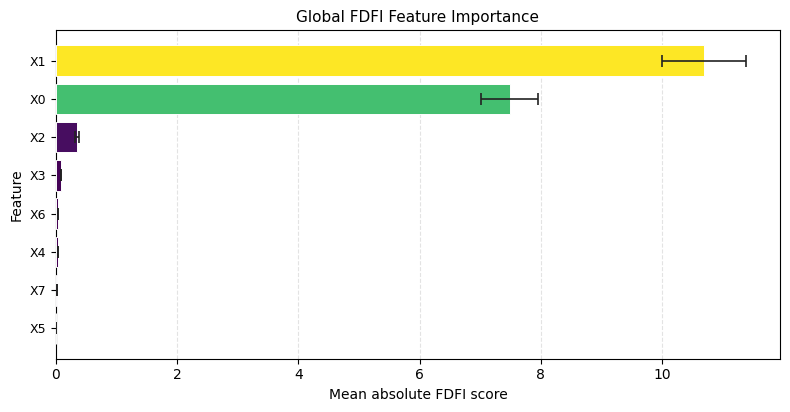

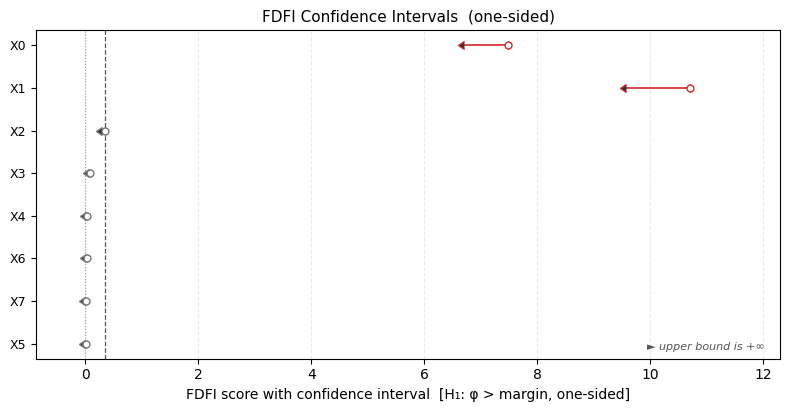

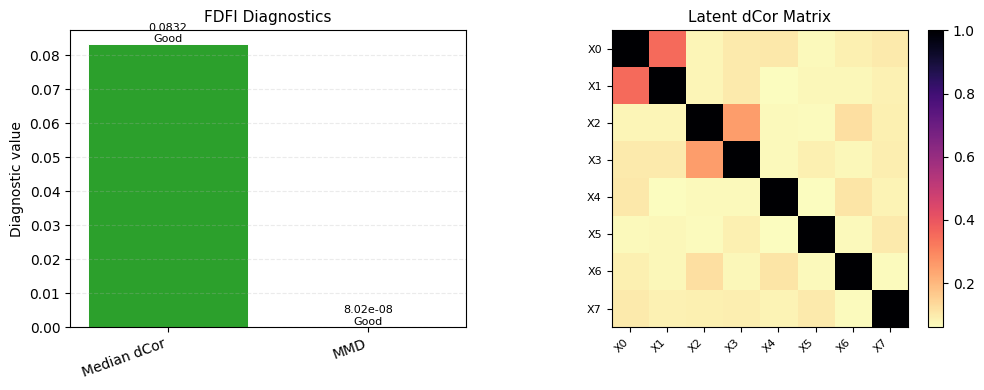

In [7]:
# Shared diagnostics (computed automatically)
flow_diag = explainer_cpi.diagnostics
print("Flow diagnostics")
print("-" * 72)
print(f"Latent independence (median dCor): {flow_diag['latent_independence_median']:.6f} [{flow_diag['latent_independence_label']}]")
print(f"Distribution fidelity (MMD):       {flow_diag['distribution_fidelity_mmd']:.6f} [{flow_diag['distribution_fidelity_label']}]")

# Standardized inference summary (v0.0.2 defaults use mixture methods)
print("\nX-space summary")
explainer_cpi.summary(alpha=0.05, target='X', alternative='greater')


feature_names = [f"X{i}" for i in range(n_features)]
summary_bar(
    results_cpi.get_phi_X(),
    results_cpi.get_se_X(),
    feature_names,
    show=False,
)

ci_flow = explainer_cpi.conf_int(alpha=0.05, target="X", alternative="greater")
confidence_interval_plot(ci_flow, feature_names=feature_names, show=False)
diagnostics_plot(flow_diag, feature_names=feature_names, show=False)


## Sampling Methods

FlowExplainer supports different ways to generate counterfactual values in Z-space:

- `'resample'`: Sample from background data (default)
- `'permutation'`: Permute within test set
- `'normal'`: Sample from standard normal
- `'condperm'`: Conditional permutation (regress Z_j | Z_{-j})

In [8]:
# Try different sampling methods
sampling_methods = ['resample', 'permutation', 'normal']
results_by_method = {}

for method in sampling_methods:
    exp = FlowExplainer(
        model, X_train,
        sampling_method=method,
        nsamples=30,
        num_steps=200,
        random_state=42,
    )
    results_by_method[method] = exp(X_test)

print("Importance by Sampling Method:")
print("-" * 55)
print(f"{'Feature':>8} {'resample':>12} {'permutation':>12} {'normal':>12}")
print("-" * 55)
for i in range(n_features):
    r = results_by_method['resample'].get_phi_X()[i]
    p = results_by_method['permutation'].get_phi_X()[i]
    n = results_by_method['normal'].get_phi_X()[i]
    print(f"{i:>8} {r:>12.4f} {p:>12.4f} {n:>12.4f}")

[FDFI][INFO] Training flow model...


Training complete: 200 steps, final loss=1.7161
[FDFI][DIAG] Flow Model Diagnostics
[FDFI][DIAG] Latent independence (median dCor): 0.083235 [GOOD]  -> lower is better
[FDFI][DIAG] Distribution fidelity (MMD):       0.000000 [GOOD]  -> lower is better


[FDFI][INFO] Training flow model...


Training complete: 200 steps, final loss=1.7161
[FDFI][DIAG] Flow Model Diagnostics
[FDFI][DIAG] Latent independence (median dCor): 0.083235 [GOOD]  -> lower is better
[FDFI][DIAG] Distribution fidelity (MMD):       0.000000 [GOOD]  -> lower is better


[FDFI][INFO] Training flow model...


Training complete: 200 steps, final loss=1.7161
[FDFI][DIAG] Flow Model Diagnostics
[FDFI][DIAG] Latent independence (median dCor): 0.083235 [GOOD]  -> lower is better
[FDFI][DIAG] Distribution fidelity (MMD):       0.000000 [GOOD]  -> lower is better


Importance by Sampling Method:
-------------------------------------------------------
 Feature     resample  permutation       normal
-------------------------------------------------------
       0       7.4857       7.5354       7.4394
       1      10.6929      10.9420      10.6173
       2       0.3499       0.3744       0.3581
       3       0.0833       0.0882       0.0891
       4       0.0317       0.0331       0.0327
       5       0.0088       0.0089       0.0096
       6       0.0323       0.0322       0.0335
       7       0.0109       0.0114       0.0115


## Using a Custom Flow Model

You can train a flow model separately and pass it to FlowExplainer. This is useful when:
- You want more control over flow training
- You have a pre-trained flow
- You want to use the same flow for multiple explainers

In [9]:
from fdfi.models import FlowMatchingModel

# Train a custom flow model
custom_flow = FlowMatchingModel(
    X=X_train,
    dim=n_features,
    hidden_dim=64,
    num_blocks=2,
)
custom_flow.fit(num_steps=300, verbose='final')

# Use the pre-trained flow
explainer_custom = FlowExplainer(
    model,
    data=X_train,
    flow_model=custom_flow,  # Pass pre-trained flow
    fit_flow=False,          # Don't retrain
    nsamples=30,
    random_state=42,
)

results_custom = explainer_custom(X_test)
print("\nImportance with custom flow:", results_custom.get_phi_X()[:4].round(4))

Training complete: 300 steps, final loss=1.5140
[FDFI][DIAG] Flow Model Diagnostics
[FDFI][DIAG] Latent independence (median dCor): 0.083218 [GOOD]  -> lower is better
[FDFI][DIAG] Distribution fidelity (MMD):       0.000000 [GOOD]  -> lower is better



Importance with custom flow: [3.6624 5.9135 0.4015 0.0669]


## Comparison: FlowExplainer vs OTExplainer

Let's compare FlowExplainer to OTExplainer on the same data:

In [10]:
# OTExplainer for comparison
explainer_ot = OTExplainer(
    model,
    data=X_train,
    nsamples=30,
    random_state=42,
)
results_ot = explainer_ot(X_test)

print("Comparison: FlowExplainer vs OTExplainer")
print("-" * 55)
print(f"{'Feature':>8} {'Flow (CPI)':>12} {'Flow (SCPI)':>12} {'OT':>12}")
print("-" * 55)
for i in range(n_features):
    f_cpi = results_cpi.get_phi_X()[i]
    f_scpi = results_scpi.get_phi_X()[i]
    ot = results_ot.get_phi_X()[i]
    print(f"{i:>8} {f_cpi:>12.4f} {f_scpi:>12.4f} {ot:>12.4f}")

# Summary statistics
active_mask = np.array([True, True, True, False, False, False, False, False])

print("\n" + "=" * 55)
print("Summary: Active vs Null Feature Importance")
print("=" * 55)
for name, phi in [('Flow CPI', results_cpi.get_phi_X()), 
                  ('Flow SCPI', results_scpi.get_phi_X()),
                  ('OT', results_ot.get_phi_X())]:
    active_mean = phi[active_mask].mean()
    null_mean = phi[~active_mask].mean()
    ratio = active_mean / null_mean if null_mean > 0 else float('inf')
    print(f"{name:>12}: active={active_mean:.4f}, null={null_mean:.4f}, ratio={ratio:.2f}x")

Comparison: FlowExplainer vs OTExplainer
-------------------------------------------------------
 Feature   Flow (CPI)  Flow (SCPI)           OT
-------------------------------------------------------
       0       7.4857       7.8085       2.8613
       1      10.6929      11.2115       5.0819
       2       0.3499       0.3937       0.2629
       3       0.0833       0.0947       0.0318
       4       0.0317       0.0372       0.0013
       5       0.0088       0.0086       0.0034
       6       0.0323       0.0337       0.0006
       7       0.0109       0.0114       0.0045

Summary: Active vs Null Feature Importance
    Flow CPI: active=6.1762, null=0.0334, ratio=184.93x
   Flow SCPI: active=6.4712, null=0.0371, ratio=174.36x
          OT: active=2.7354, null=0.0083, ratio=328.67x


## Z-space vs X-space Importance

FlowExplainer provides both:
- **phi_Z**: Importance in the disentangled latent space
- **phi_X**: Importance attributed to original features (via Jacobian)

| Space | Meaning |
|-------|---------|
| Z-space (phi_Z) | Importance of independent latent factors |
| X-space (phi_X) | Importance of original correlated features |

For linear transformations (like OTExplainer), these are related by `phi_X = H^T @ H @ phi_Z` where H is the Cholesky factor. For flows, the Jacobian varies with position.

## Summary

In this tutorial, you learned:

1. **FlowExplainer** uses normalizing flows for flexible, data-driven feature importance.
2. **CPI** is half the average loss difference; **SCPI** averages counterfactual predictions before applying the loss.
3. Use `method='both'` to compute CPI and SCPI simultaneously.
4. Different **sampling methods** offer different tradeoffs.
5. You can use **custom flow models** for more control.
6. Shared diagnostics and `conf_int`/`summary` provide a consistent inference workflow.
7. Strict one-sided testing (`alternative='greater'`) is useful for feature screening.

## Next Steps

- Try FlowExplainer on your own data.
- Compare X-space and Z-space significance.
- Cross-check with OT/EOT for consistency.

